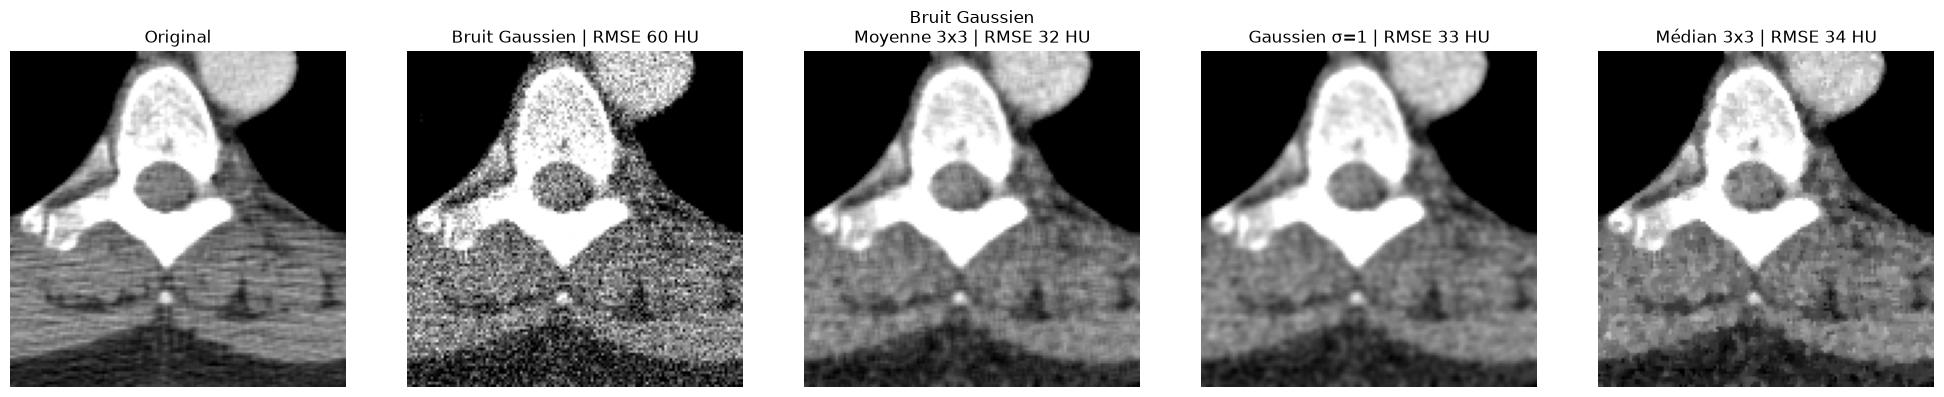

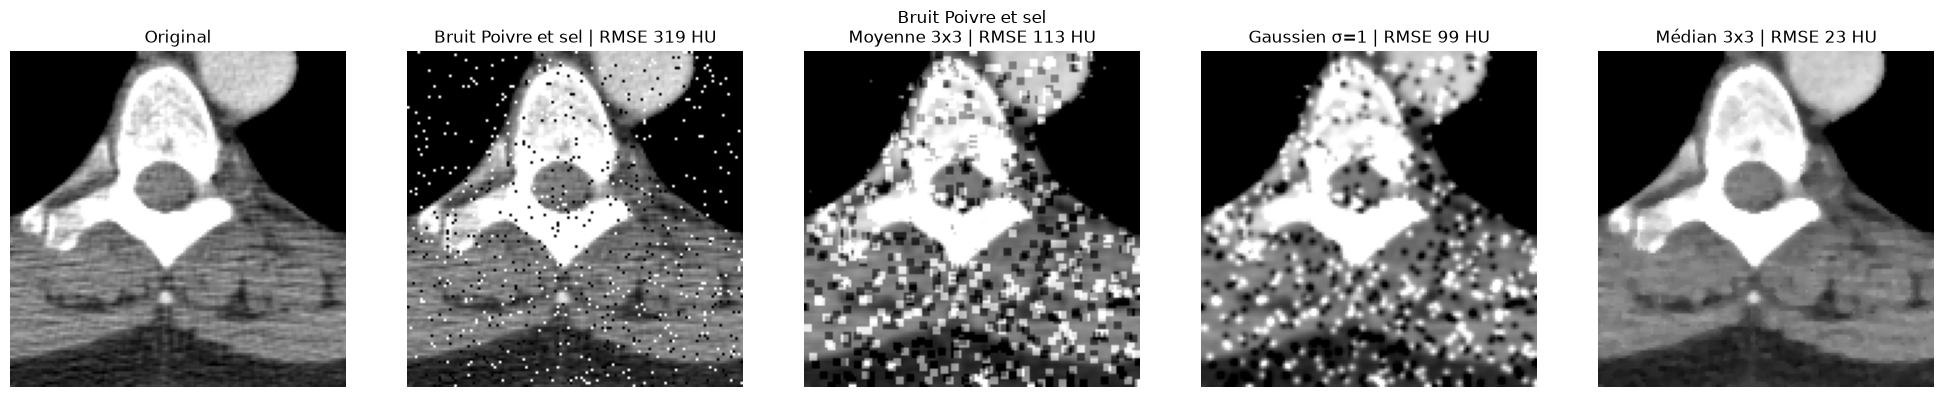

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pydicom
from pydicom.data import get_testdata_file
from scipy import ndimage as ndi

# Chargement et conversion en HU (comme en S2)
ds = pydicom.dcmread(get_testdata_file("CT_small.dcm"))
hu = ds.pixel_array.astype(np.float32) * float(ds.RescaleSlope) + float(ds.RescaleIntercept)

def fenetrage(img, centre=40, largeur=400):
    bas, haut = centre - largeur / 2, centre + largeur / 2
    return ((np.clip(img, bas, haut) - bas) / (haut - bas) * 255).astype(np.uint8)

# On ajoute deux types de bruit
rng = np.random.default_rng(0)                         # graine fixe = résultats reproductibles
bruit_gauss = hu + rng.normal(0, 60, hu.shape)         # bruit gaussien, écart-type 60 HU
bruit_ps = hu.copy()
masque = rng.random(hu.shape)
bruit_ps[masque < 0.03] = -1000                        # 3 % de pixels "poivre" (noirs)
bruit_ps[masque > 0.97] = 1500                         # 3 % de pixels "sel" (blancs)

def rmse(a, b):                                        # erreur moyenne par rapport à l'original
    return np.sqrt(np.mean((a - b) ** 2))

filtres = {
    "Moyenne 3x3": lambda im: ndi.uniform_filter(im, size=3),
    "Gaussien σ=1": lambda im: ndi.gaussian_filter(im, sigma=1),
    "Médian 3x3": lambda im: ndi.median_filter(im, size=3),
}

for nom_bruit, bruite in [("Gaussien", bruit_gauss), ("Poivre et sel", bruit_ps)]:
    fig, axes = plt.subplots(1, 5, figsize=(20, 4))
    axes[0].imshow(fenetrage(hu), cmap="gray"); axes[0].set_title("Original")
    axes[1].imshow(fenetrage(bruite), cmap="gray")
    axes[1].set_title(f"Bruit {nom_bruit} | RMSE {rmse(bruite, hu):.0f} HU")
    for ax, (nom, f) in zip(axes[2:], filtres.items()):
        filtre = f(bruite)
        ax.imshow(fenetrage(filtre), cmap="gray")
        ax.set_title(f"{nom} | RMSE {rmse(filtre, hu):.0f} HU")
    for ax in axes: ax.axis("off")
    plt.suptitle(f"Bruit {nom_bruit}"); plt.tight_layout(); plt.show()

Seuil d'Otsu : -352 HU
Seuils multi-Otsu : ['-384 HU', '196 HU']


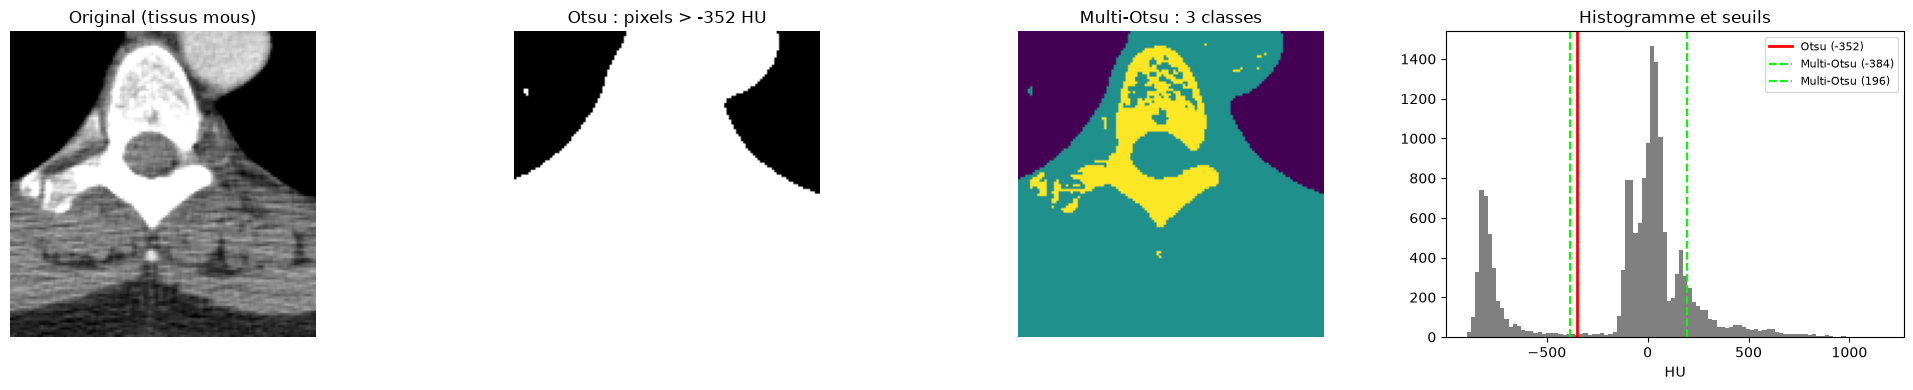

In [2]:
from skimage.filters import threshold_otsu, threshold_multiotsu

# 1. Otsu classique : 2 classes
seuil = threshold_otsu(hu)
masque = hu > seuil
print(f"Seuil d'Otsu : {seuil:.0f} HU")

# 2. Multi-Otsu : 3 classes
seuils = threshold_multiotsu(hu, classes=3)
classes = np.digitize(hu, bins=seuils)        # 0, 1 ou 2 selon la classe de chaque pixel
print("Seuils multi-Otsu :", [f"{s:.0f} HU" for s in seuils])

fig, axes = plt.subplots(1, 4, figsize=(20, 4))
axes[0].imshow(fenetrage(hu), cmap="gray"); axes[0].set_title("Original (tissus mous)")
axes[1].imshow(masque, cmap="gray"); axes[1].set_title(f"Otsu : pixels > {seuil:.0f} HU")
axes[2].imshow(classes, cmap="viridis"); axes[2].set_title("Multi-Otsu : 3 classes")
for ax in axes[:3]: ax.axis("off")

# 3. Histogramme avec les seuils trouvés
axes[3].hist(hu.ravel(), bins=100, color="gray")
axes[3].axvline(seuil, color="red", lw=2, label=f"Otsu ({seuil:.0f})")
for s in seuils:
    axes[3].axvline(s, color="lime", ls="--", label=f"Multi-Otsu ({s:.0f})")
axes[3].set_xlabel("HU"); axes[3].legend(fontsize=8); axes[3].set_title("Histogramme et seuils")
plt.tight_layout(); plt.show()

Nombre d'objets avant le tri : 5


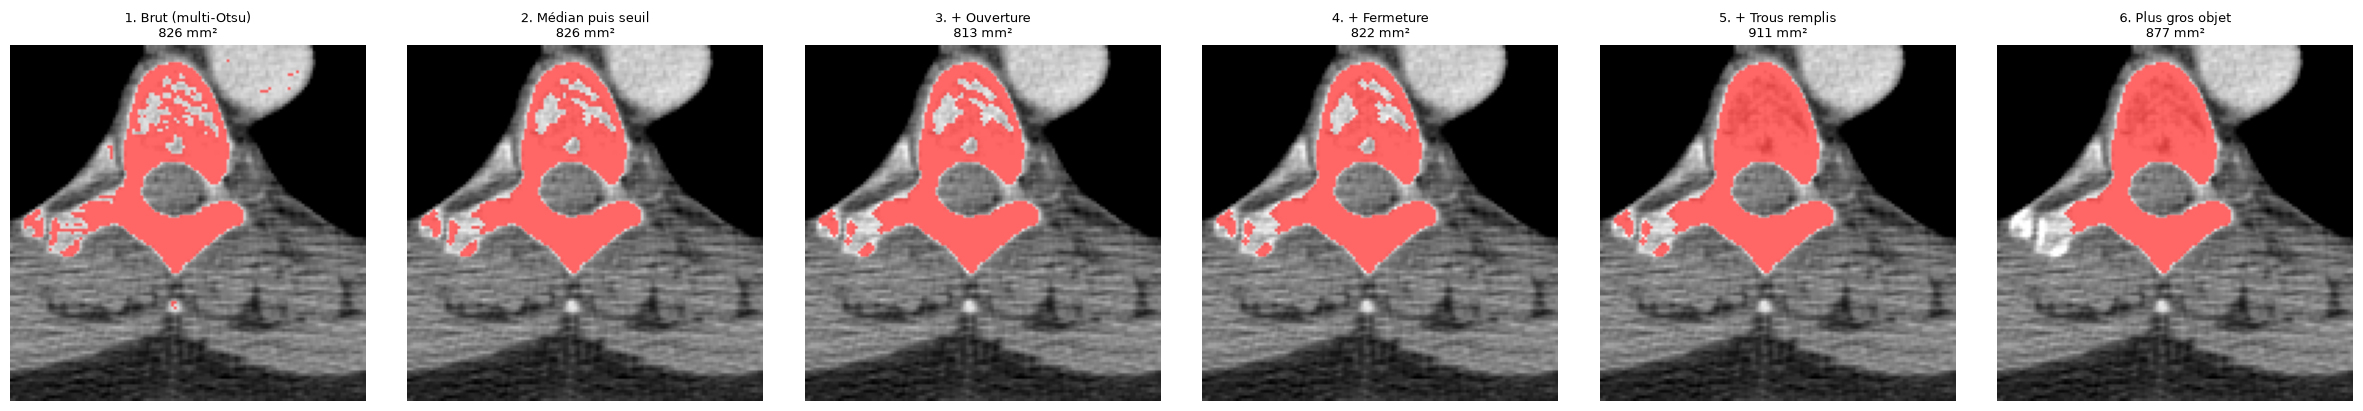

In [4]:
from skimage.morphology import disk, binary_opening, binary_closing

# 0. Masque brut de l'os (classe 2 du multi-Otsu)
os_brut = classes == 2

# 1. Variante : filtrer AVANT de seuiller (médian 3x3 de l'étape 1)
hu_median = ndi.median_filter(hu, size=3)
os_median = hu_median > seuils[1]

# 2. Ouverture : supprime les petits points isolés
os_ouvert = ndi.binary_opening(os_median, structure=disk(1))

# 3. Fermeture : bouche les petites fissures
os_ferme = ndi.binary_closing(os_ouvert, structure=disk(1))

# 4. Remplir les trous entièrement entourés d'os
os_rempli = ndi.binary_fill_holes(os_ferme)

# 5. Composantes connexes : on garde le plus gros objet
etiquettes, n = ndi.label(os_rempli)
tailles = ndi.sum(os_rempli, etiquettes, range(1, n + 1))
os_final = etiquettes == (np.argmax(tailles) + 1)
print(f"Nombre d'objets avant le tri : {n}")

# Surface en mm² à chaque étape
dy, dx = (float(v) for v in ds.PixelSpacing)
etapes = {
    "1. Brut (multi-Otsu)": os_brut,
    "2. Médian puis seuil": os_median,
    "3. + Ouverture": os_ouvert,
    "4. + Fermeture": os_ferme,
    "5. + Trous remplis": os_rempli,
    "6. Plus gros objet": os_final,
}
fig, axes = plt.subplots(1, 6, figsize=(24, 4))
for ax, (titre, m) in zip(axes, etapes.items()):
    ax.imshow(fenetrage(hu), cmap="gray")
    ax.imshow(np.ma.masked_where(~m, m), cmap="autumn", alpha=0.6)   # masque superposé en couleur
    ax.set_title(f"{titre}\n{m.sum() * dx * dy:.0f} mm²", fontsize=9)
    ax.axis("off")
plt.tight_layout(); plt.show()